In [167]:
from sedfitter.sed import SEDCube
from synphot.models import Empirical1D

import numpy as np
import matplotlib.pyplot as plt

from astropy import units as u
from synphot import units, SourceSpectrum
from synphot.models import BlackBodyNorm1D, GaussianFlux1D

import matplotlib.pyplot as plt,  matplotlib.gridspec as gridspec
from astropy.config import generate_config
generate_config(pkgname='synphot')
import numpy as np
import synphot
import astropy.constants as const

from astropy.constants import Constant
# Fetch one filter's transmission curve
from astroquery.svo_fps import SvoFps
import numpy as np
from synphot import SpectralElement
import Syn_Spec_toolkits as SSt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from tqdm import tqdm

filters = SvoFps.get_filter_list('JWST', instrument='NIRCam')

wave_pa_alpha = 1.875 * u.um
wave_br_alpha = 4.051 * u.um

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
from astropy.table import Table
t = Table.read('/net/vdesk/data2/slagter/disc_models_robitaille_2017/sp--s-i/parameters.fits')
print(t.keys())

mask_R      =  (t['star.radius']>0.9)           & (t['star.radius']<1.1)
mask_inc    =  (t['inclination']>0)             & (t['inclination']<10) # edge-on is 90 degrees
mask_T      =  (t['star.temperature']> 4900)    & (t['star.temperature']<5100)

mask        = mask_R & mask_inc & mask_T

print(np.sum(mask))
#print(t[mask])


['MODEL_NAME', 'star.radius', 'star.temperature', 'disk.mass', 'disk.rmax', 'disk.beta', 'disk.p', 'disk.h100', 'scattering', 'inclination']
5


In [ ]:
flux_path   = '/net/vdesk/data2/slagter/disc_models_robitaille_2017/sp--s-i/flux.fits'
seds        = SEDCube.read(flux_path)
systems     = {}
for name in seds.names[mask]:
    sed         = seds.get_sed(name)
    x           = 200000*u.lyr * (0.046*u.arcsec).to(u.rad).value
    ap_idx      = np.argmin((np.abs(x-sed.apertures)))
    wave        = sed.wav 
    flux        = SSt.normalize_flux(sed.flux[ap_idx], d_old=1*u.kpc, d_new = 200000*u.lyr )
    
    systems[name] = SourceSpectrum(Empirical1D, points=wave, lookup_table=flux)

names = systems.keys()

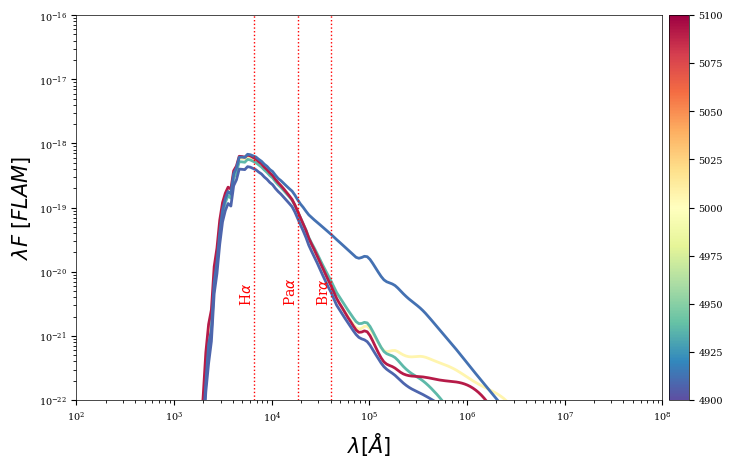

In [ ]:
fig = plt.figure(figsize=(9, 5))
gs = gridspec.GridSpec(1, 1, figure=fig,  hspace=0.3, wspace=0.2)
ax = fig.add_subplot(gs[0, 0])

vmin, vmax  = 4900, 5100
norm        = mcolors.Normalize(vmin=vmin, vmax=vmax)
cmap        = plt.get_cmap("Spectral_r")  


for name in names:
    sp = systems[name]
    inclination_system  = np.cos(t[t['MODEL_NAME'] == name]['inclination'])
    radius_system       = t[t['MODEL_NAME'] == name]['star.radius']
    temperature_system  = t[t['MODEL_NAME'] == name]['star.temperature']
    ax.plot(sp.waveset, sp(sp.waveset, flux_unit='flam'), c=cmap(norm(temperature_system)), ls='-', alpha=1, lw=2)

cbar = fig.colorbar(
    cm.ScalarMappable(norm=norm, cmap=cmap), 
    ax=ax, 
    pad = 0.01,
    orientation='vertical' 
)
ax.set_xlabel(r'$\lambda [Å]$', fontsize=15)
ax.set_ylabel(r'$\lambda F \  [FLAM]$', fontsize=15)
ax.axhline(0.3, ls='--', lw=2, c='black', label = r'$\Delta m$ = 0.3')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(1e2, 1e8)
ax.set_ylim(1e-22, 1e-16)

for lam, name in [ (0.6563, r'H$\alpha$'), (1.875, r'Pa$\alpha$'), (4.051, r'Br$\alpha$')]: #(0.3645, 'Balmer break'),
    ax.axvline(lam*1e4, lw=1, ls=':', color='red')
    ax.text(lam*1e4, 3e-21, name, color='red', rotation=90, ha='right', va='bottom')

plt.show()

In [173]:
def line_strength(Weqs, parameter_range):
    t           = Table.read('/net/vdesk/data2/slagter/disc_models_robitaille_2017/sp--s-i/parameters.fits')
    flux_path   = '/net/vdesk/data2/slagter/disc_models_robitaille_2017/sp--s-i/flux.fits'
    seds        = SEDCube.read(flux_path)
    #x           = 200000*u.lyr * (0.046*u.arcsec).to(u.rad).value
    ap_idx      = 2 #np.argmin((np.abs(x-sed.apertures)))
    names       = seds.names
    for param in parameter_range.keys():
        if parameter_range[param] != None:
            mask_i          =  (t[param] >= parameter_range[param][0]) & (t[param] < parameter_range[param][1])
            names[~mask_i]  = 'nan'

    systems     = {}
    delta_mag   = {}
    
    cleaned_names = [x for x in names if str(x) != 'nan']
    for name in cleaned_names:
        sed             = seds.get_sed(name)
        wave            = sed.wav 
        flux            = SSt.normalize_flux(sed.flux[ap_idx], d_old=1*u.kpc, d_new = 200000*u.lyr )
        systems[name]   = SourceSpectrum(Empirical1D, points=wave, lookup_table=flux)
    
    for W_eq in tqdm(Weqs, desc='Unpacking all models', position=0):
        internal = {}
        for name in tqdm(cleaned_names, desc='Per model', position=1, leave = False):
            sp_cont                 = systems[name]
            line_emission_pa        = SSt.Obtain_line_Weq( lam0         = SSt.wave_pa_alpha.to(u.AA),
                                                            W_eq        = W_eq,
                                                            continuum   = sp_cont,
                                                        )
            mag_continuum           = SSt.Compute_model_abs_MAG(    sp      = sp_cont ,
                                                                    filter  = 'F187N')
            mag_continuum_and_line  = SSt.Compute_model_abs_MAG(    sp      = sp_cont + line_emission_pa ,
                                                                    filter  = 'F187N')
            internal[name] =  mag_continuum - mag_continuum_and_line
        delta_mag[W_eq]  = internal
    
    return delta_mag

Weqs            = np.linspace(.10, 100, 20) * u.AA
parameter_range = { 'star.radius'       : (0.1, 10),
                    'star.temperature'  : (4900, 5100),
                    'disk.mass'         : None,
                    'disk.rmax'         : None,
                    'disk.beta'         : None,
                    'disk.p'            : None,
                    'disk.h100'         : None,
                    'scattering'        : None,
                    'inclination'       : (0.0, 10.0) #Edge-on is 90 degrees
                }
delta_mag = line_strength(  Weqs            = Weqs,
                            parameter_range = parameter_range
            )

names = delta_mag[Weqs[0]].keys() 
print(len(names))



Unpacking all models: 100%|██████████| 20/20 [00:52<00:00,  2.60s/it]

105


/var/tmp/slagter/ipykernel_3342330/3919339416.py:16: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(W_eq.value, y.value, c=cmap(norm(delta_mag_here)))


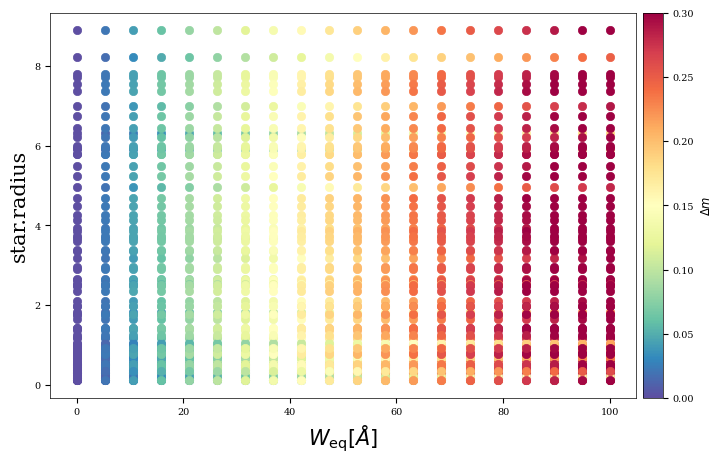

In [174]:

fig = plt.figure(figsize=(9, 5))
gs = gridspec.GridSpec(1, 1, figure=fig,  hspace=0.3, wspace=0.2)
ax = fig.add_subplot(gs[0, 0])

y_name      = 'star.radius'

vmin, vmax  = 0, 0.3
norm        = mcolors.Normalize(vmin=vmin, vmax=vmax)
cmap        = plt.get_cmap("Spectral_r")  

for W_eq in Weqs:
    internal = {}
    for name in names:
        delta_mag_here = delta_mag[W_eq][name].value
        y         = t[t['MODEL_NAME'] == name][y_name]
        ax.scatter(W_eq.value, y.value, c=cmap(norm(delta_mag_here)))

cbar = fig.colorbar(
    cm.ScalarMappable(norm=norm, cmap=cmap), 
    ax          =ax, 
    pad         = 0.01,
    orientation ='vertical' ,
    label       = r'$\Delta m$', 
)
ax.set_xlabel(r'$W_{\mathrm{eq}} [Å]$', fontsize=15)
ax.set_ylabel(y_name                  , fontsize=15)

plt.show()